In [1]:
%pip install sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [1]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"

semantic_model = SentenceTransformer(
    MODEL_NAME,
    device="cuda"
)

print("Model loaded successfully!")

C:\AI\rocm-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 49750.64it/s]


Model loaded successfully!


In [2]:
import torch
import transformers
import sentence_transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)

print("CUDA available:", torch.cuda.is_available())
print(
    "MPS available:",
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
)

PyTorch: 2.9.1+rocm7.2.1
Transformers: 5.22.1
Sentence Transformers: 6.3.0
CUDA available: True
MPS available: False


In [3]:
import json
import pandas as pd
from pathlib import Path

# Base directory
BASE_DIR = Path(
    r"C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS"
)

# File paths
GEMMA_FILE = (
    BASE_DIR / "results" / "gemma" / "prompt_v2"
    / "full_results_gemma_v2.jsonl"
)

QWEN_FILE = (
    BASE_DIR / "results" / "qwen" / "prompt_v2"
    / "full_results_qwen_v2.jsonl"
)

# Load JSONL
def load_jsonl(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        return pd.DataFrame(
            json.loads(line)
            for line in f if line.strip()
        )

gemma_df = load_jsonl(GEMMA_FILE)
qwen_df = load_jsonl(QWEN_FILE)

# Summary
for model_name, df in [
    ("GEMMA", gemma_df),
    ("QWEN", qwen_df)
]:
    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    print("Total records:", len(df))
    print("Columns:", df.columns.tolist())

    print("\nDomain distribution:")
    print(df["domain"].value_counts())

    print("\nSample record:")
    display(df.head(1))


GEMMA
Total records: 3448
Columns: ['record_id', 'source_excel_row', 'domain', 'input', 'reference', 'prediction', 'inference_time', 'status']

Domain distribution:
domain
Sentimen News    980
Penukaran Kod    799
Terjemahan       712
Sentimen         682
Campuran Kod     275
Name: count, dtype: int64

Sample record:


,record_id,source_excel_row,domain,input,reference,prediction,inference_time,status
0,Campuran Kod_3,3,Campuran Kod,{'korpus ujaran online': '1) You cannotlah lew...,{'ujaran tidak formal': 'Betul tu. Kena priori...,FORMAL: Saya faham. Saya akan memastikan tugas...,22.261873,success



QWEN
Total records: 3448
Columns: ['record_id', 'source_excel_row', 'domain', 'input', 'reference', 'prediction', 'inference_time', 'status']

Domain distribution:
domain
Sentimen News    980
Penukaran Kod    799
Terjemahan       712
Sentimen         682
Campuran Kod     275
Name: count, dtype: int64

Sample record:


,record_id,source_excel_row,domain,input,reference,prediction,inference_time,status
0,Campuran Kod_3,3,Campuran Kod,{'korpus ujaran online': '1) You cannotlah lew...,{'ujaran tidak formal': 'Betul tu. Kena priori...,FORMAL: Saya faham peringatan tersebut. Saya a...,40.49416,success


In [4]:
import re

# ==========================================
# PREPARE COSINE SIMILARITY DATA
# ==========================================

def normalize_key(value):
    return re.sub(r"\s+", " ", str(value)).strip().lower()


def get_field(data, aliases):
    if not isinstance(data, dict):
        return None

    normalized = {
        normalize_key(k): v
        for k, v in data.items()
    }

    for alias in aliases:
        key = normalize_key(alias)
        if key in normalized:
            return normalized[key]

    return None


def clean_text(value):
    if value is None:
        return ""

    return re.sub(
        r"\s+", " ", str(value)
    ).strip()


def extract_sections(prediction):
    text = str(prediction or "")

    pattern = re.compile(
        r"(?im)^\s*(?:[-*#]\s*)?"
        r"(TIDAK\s+FORMAL|FORMAL)\s*:\s*"
    )

    matches = list(pattern.finditer(text))
    sections = {}

    for i, match in enumerate(matches):
        label = re.sub(
            r"\s+", " ", match.group(1)
        ).upper()

        start = match.end()
        end = (
            matches[i + 1].start()
            if i + 1 < len(matches)
            else len(text)
        )

        sections[label] = clean_text(text[start:end])

    return sections


def prepare_cosine_data(df, model_name):

    rows = []

    for _, record in df.iterrows():

        domain = record["domain"]
        reference_data = record["reference"]
        prediction = record["prediction"]

        # Campuran Kod
        if domain == "Campuran Kod":

            sections = extract_sections(prediction)

            tasks = [
                ("Formal", "ujaran formal", "FORMAL"),
                ("Tidak Formal", "ujaran tidak formal", "TIDAK FORMAL")
            ]

            for task, alias, section_key in tasks:

                reference = clean_text(
                    get_field(reference_data, [alias])
                )

                candidate = sections.get(section_key, "")

                if reference:
                    rows.append({
                        "model": model_name,
                        "record_id": record["record_id"],
                        "domain": domain,
                        "task": task,
                        "reference": reference,
                        "prediction": candidate
                    })

        # Penukaran Kod
        elif domain == "Penukaran Kod":

            sections = extract_sections(prediction)

            tasks = [
                ("Formal", "jawapan formal", "FORMAL"),
                ("Tidak Formal", "jawapan tidak formal", "TIDAK FORMAL")
            ]

            for task, alias, section_key in tasks:

                reference = clean_text(
                    get_field(reference_data, [alias])
                )

                candidate = sections.get(section_key, "")

                if reference:
                    rows.append({
                        "model": model_name,
                        "record_id": record["record_id"],
                        "domain": domain,
                        "task": task,
                        "reference": reference,
                        "prediction": candidate
                    })

        # Terjemahan
        elif domain == "Terjemahan":

            reference = clean_text(
                get_field(
                    reference_data,
                    ["jawapan (bahasa sasaran)"]
                )
            )

            candidate = clean_text(prediction)

            if reference:
                rows.append({
                    "model": model_name,
                    "record_id": record["record_id"],
                    "domain": domain,
                    "task": "Terjemahan",
                    "reference": reference,
                    "prediction": candidate
                })

    return pd.DataFrame(rows)


# Prepare both models
gemma_cosine_df = prepare_cosine_data(
    gemma_df, "Gemma"
)

qwen_cosine_df = prepare_cosine_data(
    qwen_df, "Qwen"
)


# ==========================================
# VALIDATION
# ==========================================

for name, df in [
    ("GEMMA", gemma_cosine_df),
    ("QWEN", qwen_cosine_df)
]:

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Total evaluation pairs:", len(df))

    print("\nDomain and task distribution:")
    print(
        df.groupby(["domain", "task"]).size()
    )

    print("\nEmpty predictions:")
    print(
        df["prediction"].fillna("").str.strip().eq("").sum()
    )

    print("\nSample:")
    display(df.head(2))


GEMMA
Total evaluation pairs: 2686

Domain and task distribution:
domain         task        
Campuran Kod   Formal          275
               Tidak Formal    101
Penukaran Kod  Formal          799
               Tidak Formal    799
Terjemahan     Terjemahan      712
dtype: int64

Empty predictions:
34

Sample:


,model,record_id,domain,task,reference,prediction
0,Gemma,Campuran Kod_3,Campuran Kod,Formal,"Betul, kita mesti utamakan kerja Dr. Mari kita...",Saya faham. Saya akan memastikan tugasan terse...
1,Gemma,Campuran Kod_3,Campuran Kod,Tidak Formal,"Betul tu. Kena priority kerja Dr. tu. Jom, kit...","Yelah, aku tahu. Kali ni aku hantar on time, t..."



QWEN
Total evaluation pairs: 2686

Domain and task distribution:
domain         task        
Campuran Kod   Formal          275
               Tidak Formal    101
Penukaran Kod  Formal          799
               Tidak Formal    799
Terjemahan     Terjemahan      712
dtype: int64

Empty predictions:
45

Sample:


,model,record_id,domain,task,reference,prediction
0,Qwen,Campuran Kod_3,Campuran Kod,Formal,"Betul, kita mesti utamakan kerja Dr. Mari kita...",Saya faham peringatan tersebut. Saya akan mema...
1,Qwen,Campuran Kod_3,Campuran Kod,Tidak Formal,"Betul tu. Kena priority kerja Dr. tu. Jom, kit...","Eh, saya tahu lah. Takkan saya nak kena marah ..."


In [5]:
from sentence_transformers import util
import numpy as np

# ==========================================
# COSINE SIMILARITY FUNCTION
# ==========================================

def calculate_cosine_similarity(df, model_name):

    results = df.copy()

    references = results["reference"].fillna("").tolist()
    predictions = results["prediction"].fillna("").tolist()

    scores = np.zeros(len(results), dtype=float)

    valid_indices = [
        i for i, pred in enumerate(predictions)
        if str(pred).strip() != ""
    ]

    if valid_indices:

        valid_refs = [
            references[i] for i in valid_indices
        ]

        valid_preds = [
            predictions[i] for i in valid_indices
        ]

        ref_embeddings = semantic_model.encode(
            valid_refs,
            batch_size=16,
            convert_to_tensor=True,
            normalize_embeddings=True,
            show_progress_bar=True
        )

        pred_embeddings = semantic_model.encode(
            valid_preds,
            batch_size=16,
            convert_to_tensor=True,
            normalize_embeddings=True,
            show_progress_bar=True
        )

        similarity = util.cos_sim(
            pred_embeddings,
            ref_embeddings
        )

        similarity_scores = (
            similarity.diagonal().cpu().numpy()
        )

        for j, original_index in enumerate(valid_indices):
            scores[original_index] = similarity_scores[j]

    results["cosine_similarity"] = scores
    results["valid_prediction"] = [
        i in valid_indices for i in range(len(results))
    ]

    print(f"\n{model_name} Cosine Similarity completed")
    print("Total pairs:", len(results))
    print("Valid predictions:", len(valid_indices))
    print("Empty predictions:", len(results) - len(valid_indices))
    print("Mean cosine similarity:", round(scores.mean(), 4))

    return results


# ==========================================
# RUN BOTH MODELS
# ==========================================

gemma_cosine_results = calculate_cosine_similarity(
    gemma_cosine_df,
    "Gemma"
)

qwen_cosine_results = calculate_cosine_similarity(
    qwen_cosine_df,
    "Qwen"
)

Batches:   0%|          | 0/166 [00:00<?, ?it/s]C:\AI\rocm-env\Lib\site-packages\transformers\integrations\sdpa_attention.py:174: UserWarning: Flash Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at C:\b\pytorch\aten\src\ATen\native\transformers\hip\sdp_utils.cpp:310.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(
C:\AI\rocm-env\Lib\site-packages\transformers\integrations\sdpa_attention.py:174: UserWarning: Mem Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at C:\b\pytorch\aten\src\ATen\native\transformers\hip\sdp_utils.cpp:361.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(
Batches: 100%|██████████| 166/166 [00:18<00:00,  9.15it/s]



Gemma Cosine Similarity completed
Total pairs: 2686
Valid predictions: 2652
Empty predictions: 34
Mean cosine similarity: 0.7012


Batches: 100%|██████████| 166/166 [00:27<00:00,  6.11it/s]


Qwen Cosine Similarity completed
Total pairs: 2686
Valid predictions: 2641
Empty predictions: 45
Mean cosine similarity: 0.7028


In [6]:
# ==========================================
# COSINE SIMILARITY DETAILED ANALYSIS
# ==========================================

def analyze_cosine_results(df, model_name):

    summary = (
        df.groupby(["domain", "task"])
        .agg(
            total_pairs=("cosine_similarity", "size"),
            valid_predictions=("valid_prediction", "sum"),
            mean_with_empty=("cosine_similarity", "mean"),
            mean_without_empty=(
                "cosine_similarity",
                lambda x: x[df.loc[x.index, "valid_prediction"]].mean()
            ),
            median=("cosine_similarity", "median"),
            minimum=("cosine_similarity", "min"),
            maximum=("cosine_similarity", "max")
        )
        .reset_index()
    )

    print("\n" + "=" * 70)
    print(model_name, "- COSINE SIMILARITY ANALYSIS")
    print("=" * 70)

    display(summary.round(4))

    print("\nOVERALL RESULTS")

    print(
        "Mean including empty:",
        round(df["cosine_similarity"].mean(), 4)
    )

    print(
        "Mean excluding empty:",
        round(
            df.loc[
                df["valid_prediction"],
                "cosine_similarity"
            ].mean(),
            4
        )
    )

    print(
        "Median:",
        round(df["cosine_similarity"].median(), 4)
    )

    return summary


gemma_cosine_summary = analyze_cosine_results(
    gemma_cosine_results,
    "GEMMA"
)

qwen_cosine_summary = analyze_cosine_results(
    qwen_cosine_results,
    "QWEN"
)


GEMMA - COSINE SIMILARITY ANALYSIS


,domain,task,total_pairs,valid_predictions,mean_with_empty,mean_without_empty,median,minimum,maximum
0,Campuran Kod,Formal,275,270,0.5821,0.5929,0.6190,-0.0401,0.9612
1,Campuran Kod,Tidak Formal,101,101,0.6501,0.6501,0.6413,0.3058,0.9318
2,Penukaran Kod,Formal,799,793,0.6473,0.6522,0.6671,-0.0260,0.9904
3,Penukaran Kod,Tidak Formal,799,792,0.6128,0.6183,0.6418,0.0000,0.9758
4,Terjemahan,Terjemahan,712,696,0.9141,0.9351,0.9562,0.0000,1.0000



OVERALL RESULTS
Mean including empty: 0.7012
Mean excluding empty: 0.7102
Median: 0.7045

QWEN - COSINE SIMILARITY ANALYSIS


,domain,task,total_pairs,valid_predictions,mean_with_empty,mean_without_empty,median,minimum,maximum
0,Campuran Kod,Formal,275,274,0.6161,0.6183,0.6523,-0.0886,0.9578
1,Campuran Kod,Tidak Formal,101,101,0.7118,0.7118,0.7348,0.3157,0.9230
2,Penukaran Kod,Formal,799,796,0.6538,0.6563,0.6758,0.0000,0.9609
3,Penukaran Kod,Tidak Formal,799,788,0.6183,0.6269,0.6443,0.0000,0.9348
4,Terjemahan,Terjemahan,712,682,0.8849,0.9238,0.9435,0.0000,1.0000



OVERALL RESULTS
Mean including empty: 0.7028
Mean excluding empty: 0.7148
Median: 0.7144


In [7]:
# ==========================================
# 1. CATEGORIZE COSINE SIMILARITY SCORES
# ==========================================

import numpy as np
import pandas as pd

bins = [-np.inf, 0.50, 0.70, 0.85, np.inf]

labels = [
    "Rendah",
    "Sederhana",
    "Agak Tinggi",
    "Tinggi"
]

def categorize_scores(df):

    result = df.copy()

    result["similarity_category"] = pd.cut(
        result["cosine_similarity"],
        bins=bins,
        labels=labels,
        right=False
    )

    return result


# Categorize both models
gemma_cosine_results = categorize_scores(
    gemma_cosine_results
)

qwen_cosine_results = categorize_scores(
    qwen_cosine_results
)

print("COSINE SIMILARITY CATEGORIZATION COMPLETED")

print("\nGemma:")
print(gemma_cosine_results["similarity_category"].value_counts())

print("\nQwen:")
print(qwen_cosine_results["similarity_category"].value_counts())

COSINE SIMILARITY CATEGORIZATION COMPLETED

Gemma:
similarity_category
Sederhana      901
Tinggi         757
Agak Tinggi    620
Rendah         408
Name: count, dtype: int64

Qwen:
similarity_category
Sederhana      870
Tinggi         728
Agak Tinggi    698
Rendah         390
Name: count, dtype: int64


In [8]:
# ==========================================
# 2. MODEL COMPARISON MATRIX
# ==========================================

combined_df = pd.concat(
    [gemma_cosine_results, qwen_cosine_results],
    ignore_index=True
)

comparison = (
    combined_df
    .groupby(
        ["domain", "task", "model", "similarity_category"],
        observed=False
    )
    .size()
    .reset_index(name="count")
)

comparison["percentage"] = (
    comparison["count"] /
    comparison.groupby(
        ["domain", "task", "model"]
    )["count"].transform("sum") * 100
)

comparison["percentage"] = comparison["percentage"].round(2)

print("SEMANTIC SIMILARITY DISTRIBUTION")
display(comparison)

SEMANTIC SIMILARITY DISTRIBUTION


,domain,task,model,similarity_category,count,percentage
0,Campuran Kod,Formal,Gemma,Rendah,78,28.36
1,Campuran Kod,Formal,Gemma,Sederhana,119,43.27
2,Campuran Kod,Formal,Gemma,Agak Tinggi,65,23.64
3,Campuran Kod,Formal,Gemma,Tinggi,13,4.73
4,Campuran Kod,Formal,Qwen,Rendah,61,22.18
5,Campuran Kod,Formal,Qwen,Sederhana,119,43.27
6,Campuran Kod,Formal,Qwen,Agak Tinggi,84,30.55
7,Campuran Kod,Formal,Qwen,Tinggi,11,4.00
8,Campuran Kod,Tidak Formal,Gemma,Rendah,14,13.86
9,Campuran Kod,Tidak Formal,Gemma,Sederhana,52,51.49


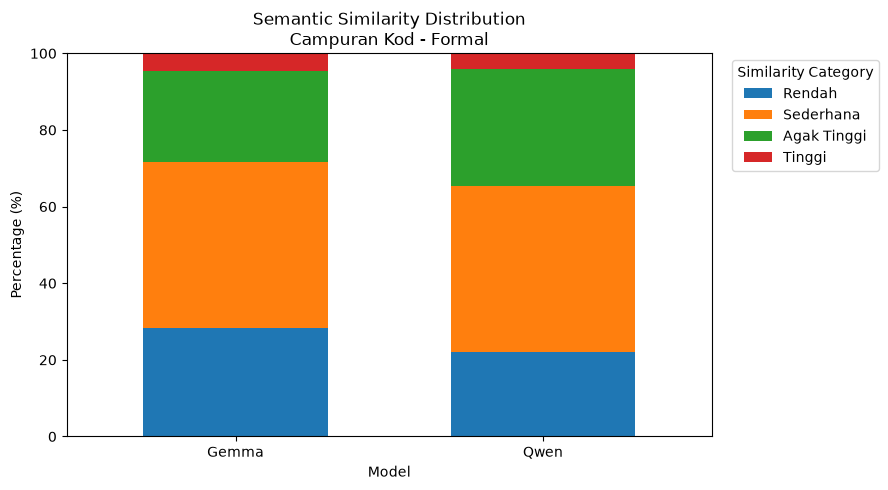

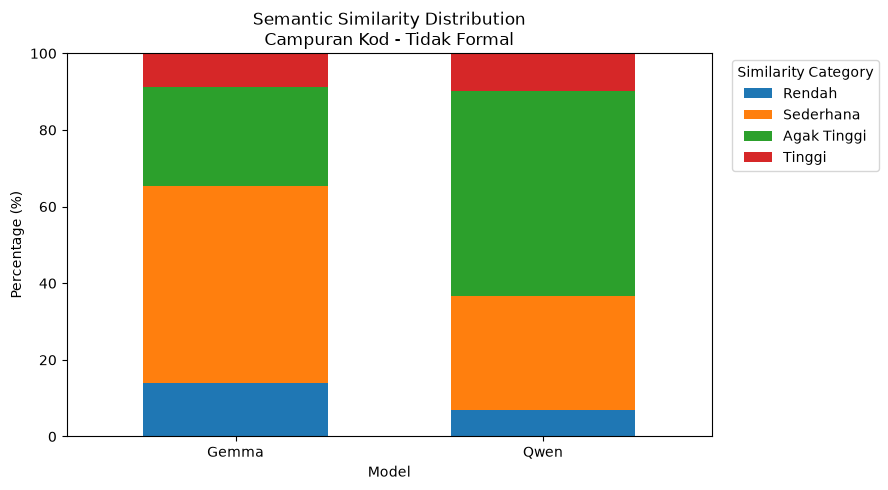

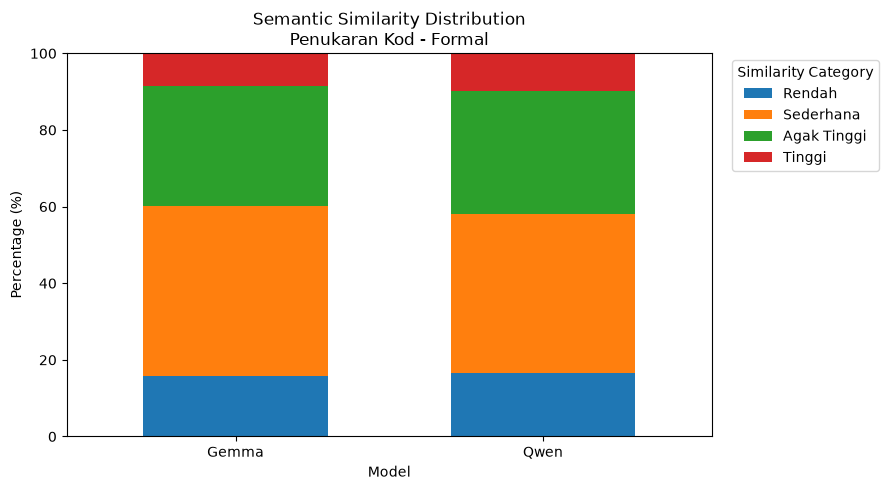

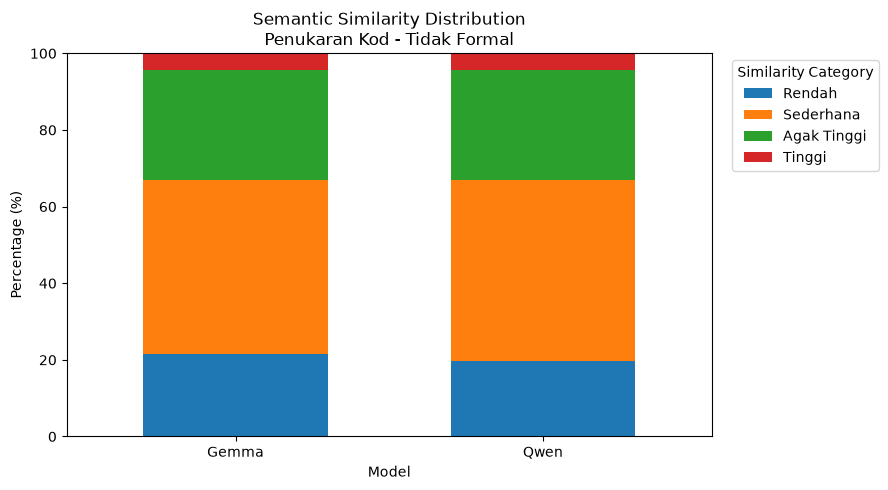

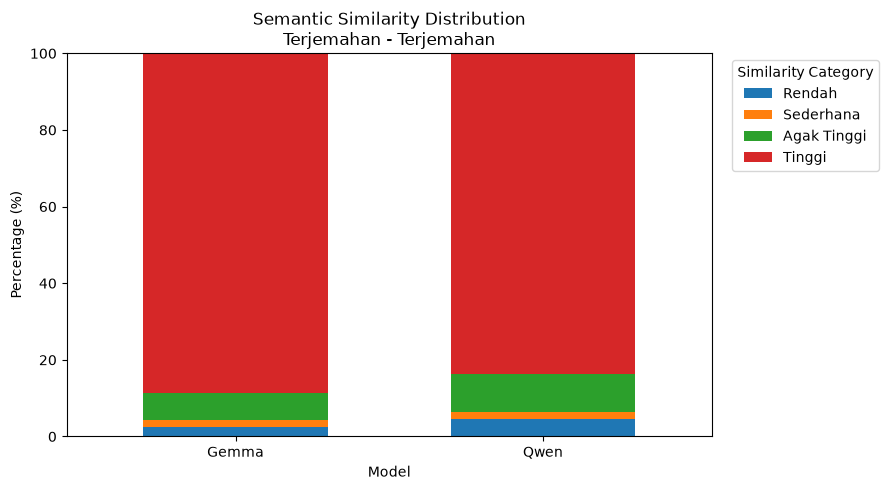

In [9]:
# ==========================================
# 3. VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt

tasks = combined_df[
    ["domain", "task"]
].drop_duplicates().values.tolist()

for domain, task in tasks:

    subset = comparison[
        (comparison["domain"] == domain) &
        (comparison["task"] == task)
    ]

    pivot = subset.pivot(
        index="model",
        columns="similarity_category",
        values="percentage"
    ).reindex(
        index=["Gemma", "Qwen"],
        columns=labels,
        fill_value=0
    ).fillna(0)

    ax = pivot.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5),
        width=0.6
    )

    plt.title(
        f"Semantic Similarity Distribution\n{domain} - {task}"
    )
    plt.xlabel("Model")
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=0)
    plt.ylim(0, 100)
    plt.legend(title="Similarity Category", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

In [10]:
# ==========================================
# SAVE SEMANTIC SIMILARITY RESULTS
# ==========================================

from pathlib import Path

OUTPUT_DIR = (
    BASE_DIR / "results" / "semantic_similarity"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save individual model results
gemma_cosine_results.to_csv(
    OUTPUT_DIR / "gemma_cosine_similarity.csv",
    index=False,
    encoding="utf-8-sig"
)

qwen_cosine_results.to_csv(
    OUTPUT_DIR / "qwen_cosine_similarity.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save combined category distribution
comparison.to_csv(
    OUTPUT_DIR / "semantic_similarity_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

print("SEMANTIC SIMILARITY RESULTS SAVED")
print("Output directory:", OUTPUT_DIR)
print("\nFiles:")
print("1. gemma_cosine_similarity.csv")
print("2. qwen_cosine_similarity.csv")
print("3. semantic_similarity_distribution.csv")

SEMANTIC SIMILARITY RESULTS SAVED
Output directory: C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\semantic_similarity

Files:
1. gemma_cosine_similarity.csv
2. qwen_cosine_similarity.csv
3. semantic_similarity_distribution.csv


In [11]:
from pathlib import Path

BASE_DIR = Path(
    r"C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS"
)

print("EVALUATION FILES")
print("=" * 60)

for file in BASE_DIR.rglob("evaluation_results*.csv"):
    print(file)

print("\nCOSINE SIMILARITY FILES")
print("=" * 60)

for file in (
    BASE_DIR / "results" / "semantic_similarity"
).glob("*.csv"):
    print(file)

EVALUATION FILES
C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\qwen\evaluation_results_qwen.csv

COSINE SIMILARITY FILES
C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\semantic_similarity\gemma_cosine_similarity.csv
C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\semantic_similarity\qwen_cosine_similarity.csv
C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\semantic_similarity\semantic_similarity_distribution.csv


In [12]:
# ==========================================
# FIND GEMMA EVALUATION FILES
# ==========================================

GEMMA_RESULTS_DIR = BASE_DIR / "results" / "gemma"

print("GEMMA RESULT FILES")
print("=" * 60)

for file in GEMMA_RESULTS_DIR.rglob("*.csv"):
    print(file)

GEMMA RESULT FILES
C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\evaluation\gemma_v2_text_generation_metrics.csv
C:\Users\WaRiSAN-01\TESTING_MODEL_HANIS\results\gemma\prompt_v2\evaluation\.ipynb_checkpoints\gemma_v2_text_generation_metrics-checkpoint.csv


In [13]:
# ==========================================
# INSPECT GEMMA AND QWEN EVALUATION FILES
# ==========================================

GEMMA_METRICS_FILE = (
    BASE_DIR / "results" / "gemma" / "prompt_v2"
    / "evaluation" / "gemma_v2_text_generation_metrics.csv"
)

QWEN_METRICS_FILE = (
    BASE_DIR / "results" / "qwen"
    / "evaluation_results_qwen.csv"
)

gemma_metrics_df = pd.read_csv(GEMMA_METRICS_FILE)
qwen_metrics_df = pd.read_csv(QWEN_METRICS_FILE)

print("=" * 60)
print("GEMMA V2 METRICS")
print("=" * 60)

print("Columns:", gemma_metrics_df.columns.tolist())
display(gemma_metrics_df)

print("\n" + "=" * 60)
print("QWEN V2 METRICS")
print("=" * 60)

print("Columns:", qwen_metrics_df.columns.tolist())
display(qwen_metrics_df)

GEMMA V2 METRICS
Columns: ['Domain', 'Style', 'Total Records', 'Reference Available', 'Reference Coverage (%)', 'Successful Predictions', 'Empty Predictions', 'Prediction Coverage (%)', 'Exact Match (%)', 'BLEU', 'chrF++', 'BERTScore Precision', 'BERTScore Recall', 'BERTScore F1']


,Domain,Style,Total Records,Reference Available,Reference Coverage (%),Successful Predictions,Empty Predictions,Prediction Coverage (%),Exact Match (%),BLEU,chrF++,BERTScore Precision,BERTScore Recall,BERTScore F1
0,Campuran Kod,Formal,275,275,100.00,270,5,98.18,0.00,2.34,20.63,0.8830,0.8702,0.8763
1,Campuran Kod,Informal,275,101,36.73,101,0,100.00,0.00,4.40,25.01,0.9033,0.9042,0.9036
2,Penukaran Kod,Formal,799,799,100.00,793,6,99.25,0.00,2.95,22.48,0.8881,0.8755,0.8814
3,Penukaran Kod,Informal,799,799,100.00,792,7,99.12,0.00,1.14,15.52,0.8814,0.8651,0.8729
4,Terjemahan,Translation,712,712,100.00,696,16,97.75,0.28,37.06,60.98,0.9373,0.9356,0.9363



QWEN V2 METRICS
Columns: ['domain', 'task', 'total', 'valid_predictions', 'invalid_predictions', 'valid_rate_percent', 'exact_match_percent', 'BLEU', 'chrF++', 'BERTScore_P', 'BERTScore_R', 'BERTScore_F1', 'accuracy_percent', 'precision_macro_percent', 'recall_macro_percent', 'f1_macro_percent', 'f1_weighted_percent']


,domain,task,total,valid_predictions,invalid_predictions,valid_rate_percent,exact_match_percent,BLEU,chrF++,BERTScore_P,BERTScore_R,BERTScore_F1,accuracy_percent,precision_macro_percent,recall_macro_percent,f1_macro_percent,f1_weighted_percent
0,Campuran Kod,Formal,275,274,1,99.64,0.00,2.3008,27.1310,0.8713,0.8918,0.8812,NaN,NaN,NaN,NaN,NaN
1,Campuran Kod,Tidak Formal,101,101,0,100.00,0.00,2.6066,27.6539,0.8769,0.9139,0.8949,NaN,NaN,NaN,NaN,NaN
2,Penukaran Kod,Formal,799,796,3,99.62,0.00,3.0160,29.5512,0.8621,0.8862,0.8737,NaN,NaN,NaN,NaN,NaN
3,Penukaran Kod,Tidak Formal,799,788,11,98.62,0.00,1.1289,21.5336,0.8438,0.8674,0.8552,NaN,NaN,NaN,NaN,NaN
4,Terjemahan,Terjemahan,712,682,30,95.79,0.28,30.5275,54.2088,0.9023,0.9043,0.9032,NaN,NaN,NaN,NaN,NaN
5,Sentimen,Classification,682,682,0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,76.98,72.67,72.37,72.51,76.82
6,Sentimen News,Classification,980,980,0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,62.45,68.55,63.52,62.62,64.12


In [14]:
# ==========================================
# FINAL TEXT GENERATION COMPARISON
# GEMMA V2 vs QWEN V2
# ==========================================

# 1. Standardize task names

def standardize_task(value):
    value = str(value).strip().lower()

    mapping = {
        "informal": "Tidak Formal",
        "tidak formal": "Tidak Formal",
        "formal": "Formal",
        "translation": "Terjemahan",
        "terjemahan": "Terjemahan"
    }

    return mapping.get(value, value.title())


# 2. Prepare Gemma metrics

gemma_text = gemma_metrics_df.copy()

gemma_text["task"] = gemma_text["Style"].apply(
    standardize_task
)

gemma_text["domain"] = gemma_text["Domain"]

gemma_text = gemma_text.rename(columns={
    "BLEU": "BLEU",
    "chrF++": "chrF++",
    "BERTScore F1": "BERTScore F1"
})

gemma_text = gemma_text[
    [
        "domain", "task",
        "BLEU", "chrF++", "BERTScore F1"
    ]
].copy()

gemma_text["model"] = "Gemma"


# 3. Prepare Qwen metrics

qwen_text = qwen_metrics_df[
    qwen_metrics_df["domain"].isin([
        "Campuran Kod",
        "Penukaran Kod",
        "Terjemahan"
    ])
].copy()

qwen_text["task"] = qwen_text["task"].apply(
    standardize_task
)

qwen_text = qwen_text.rename(columns={
    "BERTScore_F1": "BERTScore F1"
})

qwen_text = qwen_text[
    [
        "domain", "task",
        "BLEU", "chrF++", "BERTScore F1"
    ]
].copy()

qwen_text["model"] = "Qwen"


# 4. Combine text metrics

text_comparison = pd.concat(
    [gemma_text, qwen_text],
    ignore_index=True
)


# 5. Calculate cosine similarity by task

def cosine_summary(df, model_name):

    return (
        df.groupby(["domain", "task"])
        .agg(
            cosine_including_empty=(
                "cosine_similarity", "mean"
            ),
            cosine_valid_only=(
                "cosine_similarity",
                lambda x: x[
                    df.loc[x.index, "valid_prediction"]
                ].mean()
            )
        )
        .reset_index()
        .assign(model=model_name)
    )


gemma_cosine_summary_final = cosine_summary(
    gemma_cosine_results, "Gemma"
)

qwen_cosine_summary_final = cosine_summary(
    qwen_cosine_results, "Qwen"
)

cosine_comparison = pd.concat(
    [
        gemma_cosine_summary_final,
        qwen_cosine_summary_final
    ],
    ignore_index=True
)


# 6. Merge all metrics

final_text_comparison = text_comparison.merge(
    cosine_comparison,
    on=["domain", "task", "model"],
    how="left"
)

final_text_comparison = final_text_comparison.sort_values(
    ["domain", "task", "model"]
).reset_index(drop=True)


# 7. Display

print("=" * 90)
print("FINAL TEXT GENERATION MODEL COMPARISON")
print("=" * 90)

display(final_text_comparison.round(4))

FINAL TEXT GENERATION MODEL COMPARISON


,domain,task,BLEU,chrF++,BERTScore F1,model,cosine_including_empty,cosine_valid_only
0,Campuran Kod,Formal,2.3400,20.6300,0.8763,Gemma,0.5821,0.5929
1,Campuran Kod,Formal,2.3008,27.1310,0.8812,Qwen,0.6161,0.6183
2,Campuran Kod,Tidak Formal,4.4000,25.0100,0.9036,Gemma,0.6501,0.6501
3,Campuran Kod,Tidak Formal,2.6066,27.6539,0.8949,Qwen,0.7118,0.7118
4,Penukaran Kod,Formal,2.9500,22.4800,0.8814,Gemma,0.6473,0.6522
5,Penukaran Kod,Formal,3.0160,29.5512,0.8737,Qwen,0.6538,0.6563
6,Penukaran Kod,Tidak Formal,1.1400,15.5200,0.8729,Gemma,0.6128,0.6183
7,Penukaran Kod,Tidak Formal,1.1289,21.5336,0.8552,Qwen,0.6183,0.6269
8,Terjemahan,Terjemahan,37.0600,60.9800,0.9363,Gemma,0.9141,0.9351
9,Terjemahan,Terjemahan,30.5275,54.2088,0.9032,Qwen,0.8849,0.9238


In [15]:
# ==========================================
# CLASSIFICATION COMPARISON
# ==========================================

classification_comparison = pd.DataFrame([
    {
        "domain": "Sentimen",
        "model": "Gemma",
        "Accuracy": 78.59,
        "Macro Precision": 74.48,
        "Macro Recall": 72.26,
        "Macro F1": 72.65
    },
    {
        "domain": "Sentimen",
        "model": "Qwen",
        "Accuracy": 76.98,
        "Macro Precision": 72.67,
        "Macro Recall": 72.37,
        "Macro F1": 72.51
    },
    {
        "domain": "Sentimen News",
        "model": "Gemma",
        "Accuracy": 67.14,
        "Macro Precision": 67.31,
        "Macro Recall": 65.86,
        "Macro F1": 66.31
    },
    {
        "domain": "Sentimen News",
        "model": "Qwen",
        "Accuracy": 62.45,
        "Macro Precision": 68.55,
        "Macro Recall": 63.52,
        "Macro F1": 62.62
    }
])

print("CLASSIFICATION MODEL COMPARISON")

display(
    classification_comparison.sort_values(
        ["domain", "model"]
    )
)

CLASSIFICATION MODEL COMPARISON


,domain,model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Sentimen,Gemma,78.59,74.48,72.26,72.65
1,Sentimen,Qwen,76.98,72.67,72.37,72.51
2,Sentimen News,Gemma,67.14,67.31,65.86,66.31
3,Sentimen News,Qwen,62.45,68.55,63.52,62.62


In [ ]:
### RE-CALCULATE ###